In [20]:
import numpy as np
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [1]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

def tanh(x):
    return np.tanh(x)

def tanh_derivative(x):
    return 1 - np.tanh(x)**2

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return np.where(x > 0, 1, 0)

In [2]:
class Neuron:
    def __init__(self, input_size, activation='sigmoid'):
        self.weights = np.random.randn(input_size + 1) * 0.1
        self.activation_function = self._get_activation_function(activation)
        self.activation_derivative = self._get_activation_derivative(activation)
        self.output = None

    def _get_activation_function(self, activation):
        if activation == 'sigmoid':
            return sigmoid
        elif activation == 'tanh':
            return tanh
        elif activation == 'relu':
            return relu

    def _get_activation_derivative(self, activation):
        if activation == 'sigmoid':
            return sigmoid_derivative
        elif activation == 'tanh':
            return tanh_derivative
        elif activation == 'relu':
            return relu_derivative

    def activate(self, inputs):
        z = np.dot(inputs, self.weights[:-1]) + self.weights[-1]
        self.output = self.activation_function(z)
        return self.output

In [3]:
class Layer:
    def __init__(self, num_neurons, input_size, activation='sigmoid'):
        self.neurons = [Neuron(input_size, activation) for _ in range(num_neurons)]
        self.output = None
        self.error = None
        self.delta = None

    def forward(self, inputs):
        self.output = np.array([neuron.activate(inputs) for neuron in self.neurons])
        return self.output

In [4]:
class Network:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self, X, y, learning_rate):
        output = self.forward(X)
        error = y - output
        self.layers[-1].error = error
        self.layers[-1].delta = error * self.layers[-1].neurons[0].activation_derivative(output)

        for i in reversed(range(len(self.layers) - 1)):
            layer = self.layers[i]
            next_layer = self.layers[i + 1]
            layer.error = np.dot(next_layer.delta, np.array([neuron.weights[:-1] for neuron in next_layer.neurons]))
            layer.delta = layer.error * np.array([neuron.activation_derivative(neuron.output) for neuron in layer.neurons])

        for i in range(len(self.layers)):
            layer = self.layers[i]
            inputs = X if i == 0 else self.layers[i - 1].output
            for j, neuron in enumerate(layer.neurons):
                for k in range(len(neuron.weights) - 1):
                    neuron.weights[k] += learning_rate * layer.delta[j] * inputs[k]
                neuron.weights[-1] += learning_rate * layer.delta[j]  # Обновление смещения

    def train(self, X, y, learning_rate, epochs):
        for epoch in range(epochs):
            for xi, yi in zip(X, y):
                self.backward(xi, yi, learning_rate)

In [5]:
from sklearn.datasets import load_digits

df = load_digits()

In [6]:
print(df.images[0])
print(df.data[0])
print(df.target[0])

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]
0


In [7]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

np.random.seed(42)
digits = load_digits()

X = digits.data.astype(np.float64) / 16.0
labels = digits.target

X_train, X_test, labels_train, labels_test = train_test_split(X,labels,test_size=0.2,random_state=42,stratify=labels)

y_train = np.eye(10)[labels_train]

network = Network([
    Layer(32, 64, activation='relu'),
    Layer(10, 32, activation='sigmoid')
])

learning_rate = 0.1
epochs = 50

for epoch in range(epochs):
    indices = np.random.permutation(len(X_train))

    for idx in indices:
        network.backward(
            X_train[idx],
            y_train[idx],
            learning_rate
        )

    if (epoch + 1) % 5 == 0:
        train_outputs = np.array([
            network.forward(x)
            for x in X_train
        ])

        loss = np.mean(
            0.5 * np.sum((train_outputs - y_train) ** 2, axis=1)
        )

        train_predictions = np.argmax(train_outputs, axis=1)
        train_accuracy = np.mean(
            train_predictions == labels_train
        )

        print(
            f"Эпоха {epoch + 1:3d} | "
            f"Loss: {loss:.4f} | "
            f"Точность на обучении: {train_accuracy:.2%}"
        )

test_outputs = np.array([
    network.forward(x)
    for x in X_test
])

test_predictions = np.argmax(test_outputs, axis=1)
test_accuracy = np.mean(test_predictions == labels_test)

print(f"\nТочность на тесте: {test_accuracy:.2%}")

for i in range(10):
    print(
        f"Правильная цифра: {labels_test[i]}, "
        f"предсказание: {test_predictions[i]}"
    )

Эпоха   5 | Loss: 0.0393 | Точность на обучении: 96.45%
Эпоха  10 | Loss: 0.0233 | Точность на обучении: 97.70%
Эпоха  15 | Loss: 0.0144 | Точность на обучении: 99.03%
Эпоха  20 | Loss: 0.0111 | Точность на обучении: 99.10%
Эпоха  25 | Loss: 0.0072 | Точность на обучении: 99.23%
Эпоха  30 | Loss: 0.0061 | Точность на обучении: 99.23%
Эпоха  35 | Loss: 0.0056 | Точность на обучении: 99.30%
Эпоха  40 | Loss: 0.0053 | Точность на обучении: 99.44%
Эпоха  45 | Loss: 0.0040 | Точность на обучении: 99.44%
Эпоха  50 | Loss: 0.0037 | Точность на обучении: 99.44%

Точность на тесте: 98.33%
Правильная цифра: 5, предсказание: 5
Правильная цифра: 2, предсказание: 2
Правильная цифра: 8, предсказание: 8
Правильная цифра: 1, предсказание: 1
Правильная цифра: 7, предсказание: 7
Правильная цифра: 2, предсказание: 2
Правильная цифра: 6, предсказание: 6
Правильная цифра: 2, предсказание: 2
Правильная цифра: 6, предсказание: 6
Правильная цифра: 5, предсказание: 5


In [30]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

torch.manual_seed(42)
digits = load_digits()
X = digits.data / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_t, y_train_t)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
)



mlp = nn.Sequential(
    nn.Linear(64, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

cnn = nn.Sequential(
    nn.Unflatten(1, (1, 8, 8)),
    nn.Conv2d(1, 8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Flatten(),
    nn.Linear(512, 10)
)

In [31]:

loss_fn = nn.CrossEntropyLoss()

def train_model(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    losses = []
    accuracies = []

    for epoch in range(50):
        model.train()

        for x, y in train_loader:
            optimizer.zero_grad()

            prediction = model(x)
            loss = loss_fn(prediction, y)

            loss.backward()
            optimizer.step()

        model.eval()

        with torch.no_grad():
            prediction = model(X_train_t)

            train_loss = loss_fn(prediction, y_train_t).item()
            train_acc = (
                (prediction.argmax(1) == y_train_t)
                .float()
                .mean()
                .item()
            )

        losses.append(train_loss)
        accuracies.append(train_acc)

        print(
            f"Epoch {epoch+1}: "
            f"Loss={train_loss:.4f}, "
            f"Accuracy={train_acc:.4f}"
        )

    return losses, accuracies


In [32]:
mlp_history = train_model(mlp)

Epoch 1: Loss=1.7940, Accuracy=0.8274
Epoch 2: Loss=1.0849, Accuracy=0.8727
Epoch 3: Loss=0.6536, Accuracy=0.9019
Epoch 4: Loss=0.4493, Accuracy=0.9248
Epoch 5: Loss=0.3487, Accuracy=0.9311
Epoch 6: Loss=0.2811, Accuracy=0.9450
Epoch 7: Loss=0.2387, Accuracy=0.9541
Epoch 8: Loss=0.2074, Accuracy=0.9624
Epoch 9: Loss=0.1841, Accuracy=0.9645
Epoch 10: Loss=0.1689, Accuracy=0.9652
Epoch 11: Loss=0.1518, Accuracy=0.9680
Epoch 12: Loss=0.1359, Accuracy=0.9729
Epoch 13: Loss=0.1279, Accuracy=0.9763
Epoch 14: Loss=0.1187, Accuracy=0.9784
Epoch 15: Loss=0.1085, Accuracy=0.9812
Epoch 16: Loss=0.1036, Accuracy=0.9812
Epoch 17: Loss=0.0991, Accuracy=0.9791
Epoch 18: Loss=0.0903, Accuracy=0.9854
Epoch 19: Loss=0.0860, Accuracy=0.9854
Epoch 20: Loss=0.0797, Accuracy=0.9882
Epoch 21: Loss=0.0774, Accuracy=0.9861
Epoch 22: Loss=0.0723, Accuracy=0.9868
Epoch 23: Loss=0.0684, Accuracy=0.9882
Epoch 24: Loss=0.0669, Accuracy=0.9889
Epoch 25: Loss=0.0614, Accuracy=0.9889
Epoch 26: Loss=0.0587, Accuracy=0.

In [33]:
cnn_history = train_model(cnn)

Epoch 1: Loss=1.6643, Accuracy=0.9061
Epoch 2: Loss=0.7747, Accuracy=0.9040
Epoch 3: Loss=0.4297, Accuracy=0.9290
Epoch 4: Loss=0.3117, Accuracy=0.9367
Epoch 5: Loss=0.2525, Accuracy=0.9499
Epoch 6: Loss=0.2207, Accuracy=0.9464
Epoch 7: Loss=0.1875, Accuracy=0.9617
Epoch 8: Loss=0.1709, Accuracy=0.9631
Epoch 9: Loss=0.1555, Accuracy=0.9645
Epoch 10: Loss=0.1408, Accuracy=0.9687
Epoch 11: Loss=0.1319, Accuracy=0.9701
Epoch 12: Loss=0.1210, Accuracy=0.9743
Epoch 13: Loss=0.1131, Accuracy=0.9763
Epoch 14: Loss=0.1070, Accuracy=0.9749
Epoch 15: Loss=0.0998, Accuracy=0.9743
Epoch 16: Loss=0.0853, Accuracy=0.9819
Epoch 17: Loss=0.0807, Accuracy=0.9847
Epoch 18: Loss=0.0762, Accuracy=0.9854
Epoch 19: Loss=0.0708, Accuracy=0.9847
Epoch 20: Loss=0.0709, Accuracy=0.9826
Epoch 21: Loss=0.0624, Accuracy=0.9861
Epoch 22: Loss=0.0575, Accuracy=0.9896
Epoch 23: Loss=0.0588, Accuracy=0.9861
Epoch 24: Loss=0.0579, Accuracy=0.9882
Epoch 25: Loss=0.0497, Accuracy=0.9930
Epoch 26: Loss=0.0474, Accuracy=0.

In [34]:
mlp.eval()
cnn.eval()

with torch.no_grad():
    mlp_pred = mlp(X_test_t).argmax(1).numpy()
    cnn_pred = cnn(X_test_t).argmax(1).numpy()

In [35]:
print("MLP:", accuracy_score(y_test, mlp_pred))
print("CNN:", accuracy_score(y_test, cnn_pred))

MLP: 0.9805555555555555
CNN: 0.9722222222222222


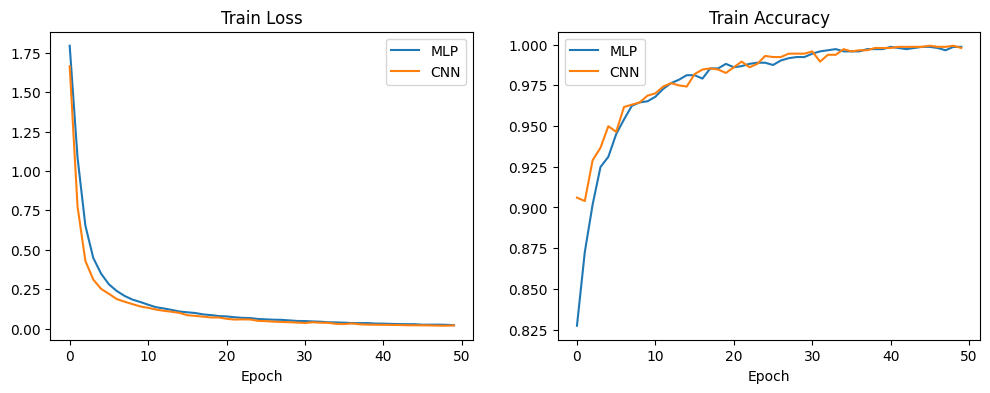

In [36]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(mlp_history[0], label="MLP")
plt.plot(cnn_history[0], label="CNN")
plt.title("Train Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(mlp_history[1], label="MLP")
plt.plot(cnn_history[1], label="CNN")
plt.title("Train Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.show()


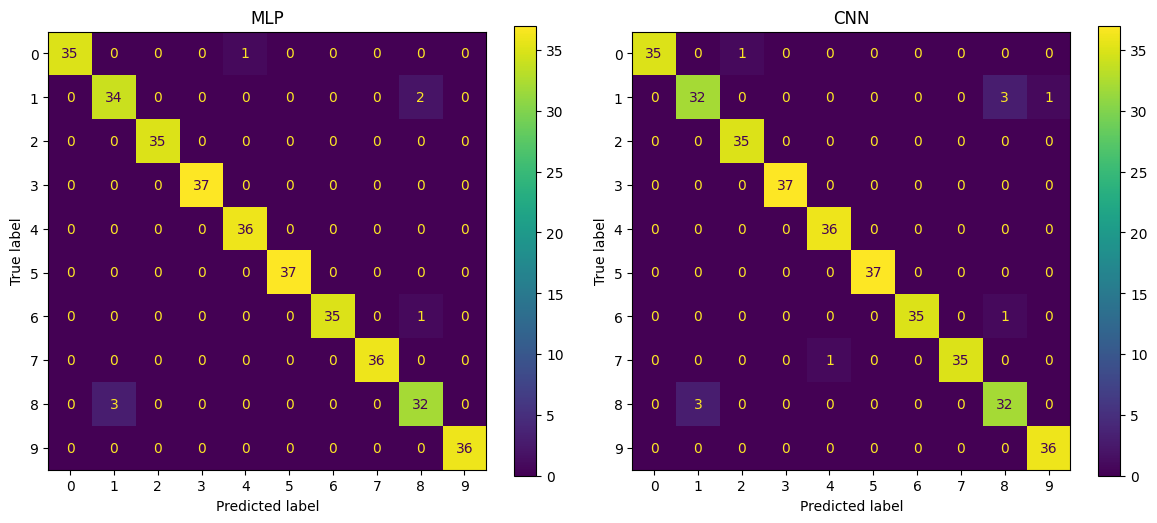

In [37]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, mlp_pred, ax=axes[0]
)
axes[0].set_title("MLP")

ConfusionMatrixDisplay.from_predictions(
    y_test, cnn_pred, ax=axes[1]
)
axes[1].set_title("CNN")

plt.tight_layout()
plt.show()
